# 01 · Linear Regression — Fitting a Line, and Gradient Descent

**Problem type:** supervised **regression** (predict a number).

**What you'll learn**
1. The intuition: "the best straight line through the points"
2. How we measure "best" — the **Mean Squared Error** loss
3. Two ways to find the best line: the **closed-form formula** and **gradient descent**
4. Building it three ways: 🐍 pure Python → 🔢 NumPy → 📦 scikit-learn
5. Extensions: multiple features, polynomial regression, overfitting, and **regularisation** (Ridge & Lasso)

Gradient descent, introduced here, is *the* training algorithm behind logistic regression, neural networks and LLMs — so take your time with Section 4.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3

## 1. Intuition

You have data on houses: size (x) and price (y). You want to predict the price of a new house from its size.

A straight line has two knobs:
$$ \hat{y} = w \cdot x + b $$
- **w** (weight / slope): how much price rises per extra m²
- **b** (bias / intercept): the price when x = 0

The hat on $\hat{y}$ means "predicted". Training = choosing **w** and **b**.

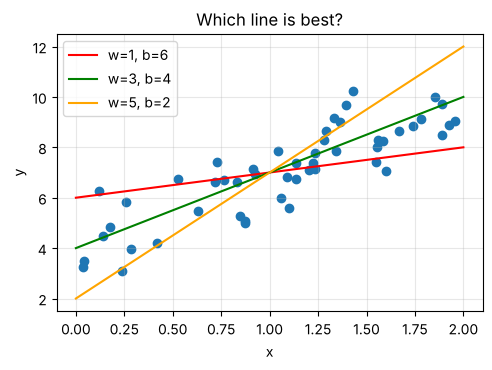

In [2]:
# Make a toy dataset: true relationship y = 3x + 4, plus random noise
n = 50
x = 2 * np.random.rand(n)            # sizes between 0 and 2
y = 4 + 3 * x + np.random.randn(n)   # noise ~ N(0,1)

plt.scatter(x, y)
for w_try, b_try, c in [(1, 6, "red"), (3, 4, "green"), (5, 2, "orange")]:
    xs = np.array([0, 2]); plt.plot(xs, w_try * xs + b_try, c=c, label=f"w={w_try}, b={b_try}")
plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Which line is best?"); plt.show()

## 2. Measuring "best": the loss function

For each point, the **residual** (error) is $y_i - \hat{y}_i$, the vertical distance from the point to the line. We square the errors (so negatives don't cancel positives, and big mistakes count extra) and average them:

$$ \text{MSE}(w, b) = \frac{1}{n} \sum_{i=1}^{n} \big(y_i - (w x_i + b)\big)^2 $$

**The best line is the one with the smallest MSE.** Let's compute it for the three lines above:

In [3]:
def mse(w, b, x, y):
    return np.mean((y - (w * x + b)) ** 2)

for w_try, b_try in [(1, 6), (3, 4), (5, 2)]:
    print(f"w={w_try}, b={b_try}  →  MSE = {mse(w_try, b_try, x, y):.3f}")

w=1, b=6  →  MSE = 1.867
w=3, b=4  →  MSE = 0.892
w=5, b=2  →  MSE = 2.336


The green line (w=3, b=4) wins — unsurprising, since that's how we generated the data. But how do we find the best **w, b** without guessing? Picture the MSE as a landscape over all possible (w, b) pairs:

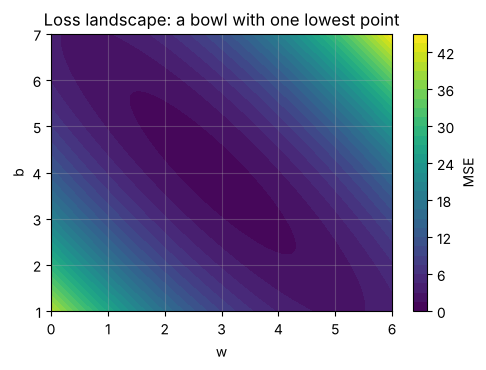

In [4]:
W, B = np.meshgrid(np.linspace(0, 6, 120), np.linspace(1, 7, 120))
L = np.array([[mse(wi, bi, x, y) for wi, bi in zip(rw, rb)] for rw, rb in zip(W, B)])
plt.contourf(W, B, L, levels=30, cmap="viridis"); plt.colorbar(label="MSE")
plt.xlabel("w"); plt.ylabel("b"); plt.title("Loss landscape: a bowl with one lowest point"); plt.show()

It's a **bowl** (mathematicians say *convex*): one lowest point, no traps. We want the bottom of the bowl. Two ways to get there:

## 3. Method 1 — the closed-form solution

For one feature, calculus (set the derivatives to zero) gives a direct formula:

$$ w = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2} = \frac{\text{cov}(x,y)}{\text{var}(x)}, \qquad b = \bar{y} - w\,\bar{x} $$

where $\bar{x}$ is the mean of x. In words: *slope = how much x and y move together ÷ how much x moves on its own.*

In [5]:
# 🐍 Pure Python closed form
def fit_line_python(xs, ys):
    n = len(xs)
    x_mean = sum(xs) / n
    y_mean = sum(ys) / n
    num = sum((xi - x_mean) * (yi - y_mean) for xi, yi in zip(xs, ys))
    den = sum((xi - x_mean) ** 2 for xi in xs)
    w = num / den
    b = y_mean - w * x_mean
    return w, b

w_py, b_py = fit_line_python(x.tolist(), y.tolist())
print(f"pure Python:  w = {w_py:.4f}, b = {b_py:.4f}")

pure Python:  w = 2.8464, b = 3.9928


With **many features**, x becomes a matrix **X** (one row per sample, one column per feature) and **w** a vector. The same idea gives the famous **normal equation**:

$$ \mathbf{w} = (X^\top X)^{-1} X^\top \mathbf{y} $$

Trick: add a column of 1s to X, and **b** becomes just another weight. In NumPy we use `np.linalg.lstsq` (or `solve`) rather than computing an inverse — it's more numerically stable.

In [6]:
# 🔢 NumPy normal equation
X_b = np.column_stack([np.ones(n), x])            # add the column of 1s → [1, x]
theta = np.linalg.solve(X_b.T @ X_b, X_b.T @ y)   # solves (XᵀX) θ = Xᵀy
print(f"NumPy:        b = {theta[0]:.4f}, w = {theta[1]:.4f}")

NumPy:        b = 3.9928, w = 2.8464


**Why not always use the formula?** Solving it costs about $d^3$ operations for $d$ features — fine for 100 features, hopeless for a million. It also only exists for a few models. For everything else we need…

## 4. Method 2 — Gradient Descent (the most important algorithm in ML)

**Analogy:** you're on a foggy hill and want to reach the valley. You can't see far, but you can feel the slope under your feet. So you take a small step **downhill**, then feel again, and repeat.

- The **gradient** is the slope: which direction makes the loss go *up* fastest, and how steeply.
- So we step in the **opposite** direction.
- The **learning rate** α controls the step size.

$$ w \leftarrow w - \alpha \frac{\partial \text{MSE}}{\partial w}, \qquad b \leftarrow b - \alpha \frac{\partial \text{MSE}}{\partial b} $$

For MSE, the derivatives (by the chain rule) are:

$$ \frac{\partial \text{MSE}}{\partial w} = -\frac{2}{n}\sum (y_i - \hat{y}_i)\,x_i, \qquad \frac{\partial \text{MSE}}{\partial b} = -\frac{2}{n}\sum (y_i - \hat{y}_i) $$

Read it: *if predictions are too low (residual positive), the gradient is negative, so we increase w and b.* Sensible!

In [7]:
# 🐍 Pure Python gradient descent — every step visible
def gd_python(xs, ys, lr=0.1, epochs=1000):
    w, b = 0.0, 0.0
    n = len(xs)
    for epoch in range(epochs):
        dw = db = 0.0
        for xi, yi in zip(xs, ys):
            error = yi - (w * xi + b)       # residual
            dw += -2 * error * xi / n
            db += -2 * error / n
        w -= lr * dw                       # step downhill
        b -= lr * db
    return w, b

w_gd, b_gd = gd_python(x.tolist(), y.tolist())
print(f"pure-Python GD: w = {w_gd:.4f}, b = {b_gd:.4f}   (closed form: w = {w_py:.4f}, b = {b_py:.4f})")

pure-Python GD: w = 2.8464, b = 3.9928   (closed form: w = 2.8464, b = 3.9928)


In [8]:
# 🔢 NumPy gradient descent — the inner loop disappears into matrix maths.
# Works for ANY number of features. Gradient in vector form: ∇ = -(2/n) Xᵀ(y - Xθ)
def gd_numpy(X, y, lr=0.1, epochs=1000, record=False):
    n, d = X.shape
    theta = np.zeros(d)
    history = []
    for _ in range(epochs):
        residual = y - X @ theta
        grad = -2 / n * X.T @ residual
        theta -= lr * grad
        if record:
            history.append((theta.copy(), np.mean(residual ** 2)))
    return (theta, history) if record else theta

theta_gd, hist = gd_numpy(X_b, y, record=True)
print("NumPy GD: b, w =", theta_gd.round(4))

NumPy GD: b, w = [3.9928 2.8464]


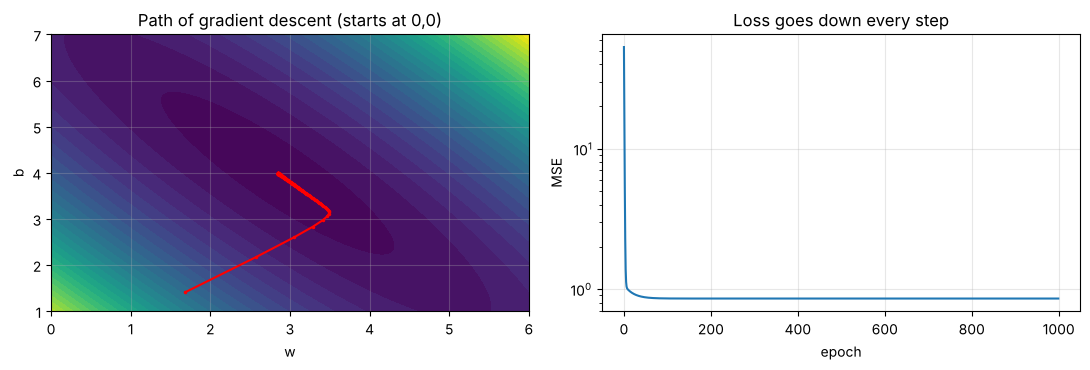

In [9]:
# Watch gradient descent walk down the bowl
path = np.array([h[0] for h in hist[:200]])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].contourf(W, B, L, levels=30, cmap="viridis")
ax[0].plot(path[:, 1], path[:, 0], "r.-", ms=3); ax[0].set_xlabel("w"); ax[0].set_ylabel("b")
ax[0].set_title("Path of gradient descent (starts at 0,0)")
ax[1].plot([h[1] for h in hist]); ax[1].set_yscale("log")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("MSE"); ax[1].set_title("Loss goes down every step")
plt.tight_layout(); plt.show()

### The learning rate matters — a lot
- **Too small:** you get there, but it takes forever.
- **Too large:** you overshoot the valley and bounce out — the loss *explodes*.

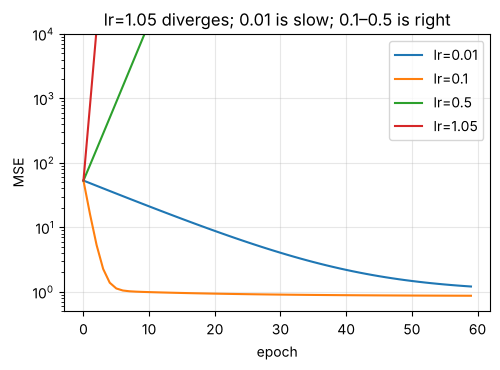

In [10]:
for lr in [0.01, 0.1, 0.5, 1.05]:
    _, h = gd_numpy(X_b, y, lr=lr, epochs=60, record=True)
    plt.plot([hi[1] for hi in h], label=f"lr={lr}")
plt.yscale("log"); plt.ylim(0.5, 1e4); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend()
plt.title("lr=1.05 diverges; 0.01 is slow; 0.1–0.5 is right"); plt.show()

**Variants you'll hear about**
- **Batch GD** (above): uses all n samples per step.
- **Stochastic GD (SGD):** one random sample per step — noisy but cheap, scales to huge data.
- **Mini-batch GD:** e.g. 32–512 samples per step — the standard in deep learning.

In [11]:
# 🔢 Mini-batch SGD in NumPy
def minibatch_sgd(X, y, lr=0.05, epochs=50, batch=8, seed=0):
    rng = np.random.default_rng(seed)
    theta = np.zeros(X.shape[1])
    for _ in range(epochs):
        idx = rng.permutation(len(y))                  # shuffle each epoch
        for start in range(0, len(y), batch):
            bi = idx[start:start + batch]
            grad = -2 / len(bi) * X[bi].T @ (y[bi] - X[bi] @ theta)
            theta -= lr * grad
    return theta

print("mini-batch SGD: b, w =", minibatch_sgd(X_b, y).round(4))

mini-batch SGD: b, w = [3.9764 2.8237]


## 5. 📦 scikit-learn — what you'd use in practice

sklearn:  w = 2.8464, b = 3.9928
All methods agree ✔


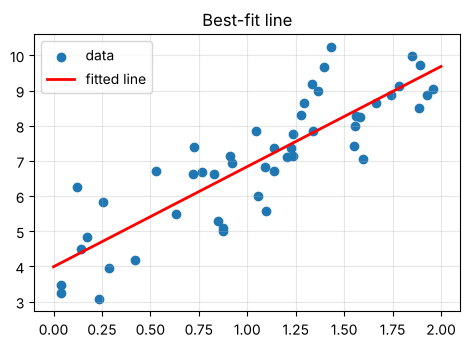

In [12]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x.reshape(-1, 1), y)      # sklearn wants X as 2-D: (n_samples, n_features)
print(f"sklearn:  w = {model.coef_[0]:.4f}, b = {model.intercept_:.4f}")
print("All methods agree ✔")

plt.scatter(x, y, label="data")
xs = np.linspace(0, 2, 10).reshape(-1, 1)
plt.plot(xs, model.predict(xs), "r", lw=2, label="fitted line")
plt.legend(); plt.title("Best-fit line"); plt.show()

## 6. Evaluating a regression model

| Metric | Formula | Meaning |
|---|---|---|
| **MSE** | mean of squared errors | penalises big errors heavily; units are squared |
| **RMSE** | √MSE | same units as y — "typical error size" |
| **MAE** | mean of absolute errors | robust to outliers |
| **R²** | 1 − SS_res / SS_tot | fraction of variance explained: 1 = perfect, 0 = no better than predicting the mean |

In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
p = model.predict(x.reshape(-1, 1))

# 🐍 R² by hand, so it's not magic
y_mean = sum(y) / len(y)
ss_res = sum((yi - pi) ** 2 for yi, pi in zip(y, p))
ss_tot = sum((yi - y_mean) ** 2 for yi in y)
print(f"R² by hand: {1 - ss_res/ss_tot:.4f}   sklearn: {r2_score(y, p):.4f}")
print(f"RMSE: {mean_squared_error(y, p) ** 0.5:.3f}   MAE: {mean_absolute_error(y, p):.3f}")

R² by hand: 0.7374   sklearn: 0.7374
RMSE: 0.925   MAE: 0.751


## 7. Multiple features — a real dataset

The **diabetes** dataset: 442 patients, 10 measurements (age, BMI, blood pressure…), target = disease progression after one year.

**Feature scaling:** when features have very different ranges, the loss bowl becomes a long thin valley and gradient descent zig-zags. **Standardising** (mean 0, std 1) makes it round. Always scale before gradient descent (and for most models — trees are the exception).

our GD test R²:   0.3322
sklearn test R²:  0.3322


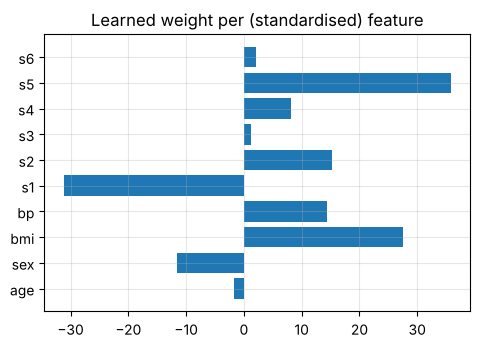

In [14]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Xd, yd = load_diabetes(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=0)

scaler = StandardScaler().fit(Xtr)            # learn mean/std on TRAIN only (no peeking at test!)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

# Our NumPy GD vs sklearn on 10 features
add1 = lambda A: np.column_stack([np.ones(len(A)), A])
theta = gd_numpy(add1(Xtr_s), ytr, lr=0.1, epochs=3000)
sk = LinearRegression().fit(Xtr_s, ytr)
print("our GD test R²:  ", round(r2_score(yte, add1(Xte_s) @ theta), 4))
print("sklearn test R²: ", round(sk.score(Xte_s, yte), 4))

names = load_diabetes().feature_names
plt.barh(names, sk.coef_); plt.title("Learned weight per (standardised) feature"); plt.show()

**Reading coefficients:** with standardised features, each weight = change in prediction when that feature rises by one standard deviation, *holding the others fixed*. Bigger |weight| ≈ more influence — but beware when features are correlated with each other (multicollinearity): weights can become unstable and misleading.

## 8. Curves with a straight-line model: polynomial regression

"Linear" regression means linear **in the weights**, not in x. Add features $x^2, x^3, \dots$ and the same algorithm fits curves:

$$ \hat{y} = w_1 x + w_2 x^2 + w_3 x^3 + b $$

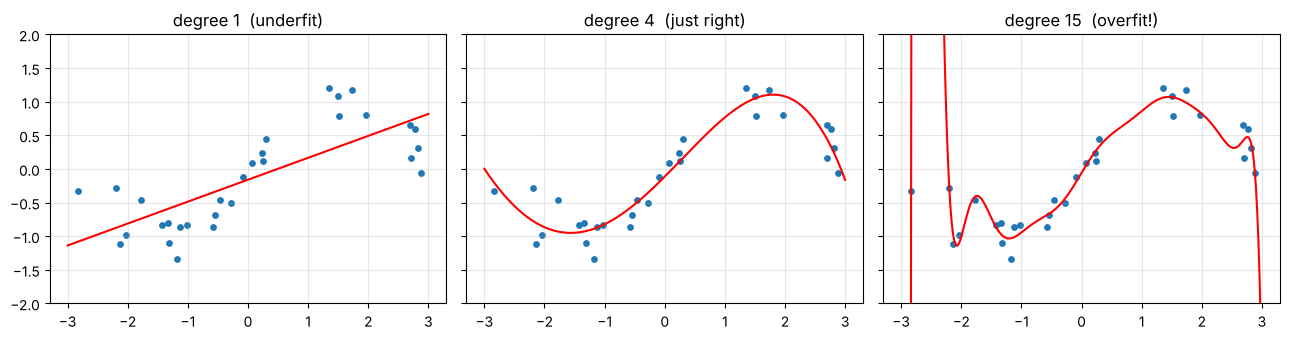

In [15]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(1)
xc = np.sort(rng.uniform(-3, 3, 30)); yc = np.sin(xc) + rng.normal(0, 0.25, 30)
grid = np.linspace(-3, 3, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, deg in zip(axes, [1, 4, 15]):
    m = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression()).fit(xc.reshape(-1, 1), yc)
    ax.scatter(xc, yc, s=15); ax.plot(grid, m.predict(grid), "r"); ax.set_ylim(-2, 2)
    ax.set_title(f"degree {deg}" + ["  (underfit)", "  (just right)", "  (overfit!)"][[1, 4, 15].index(deg)])
plt.tight_layout(); plt.show()

This picture is the **bias–variance trade-off** (more in notebook 03):
- **Underfitting (high bias):** model too simple — misses the pattern, bad on train *and* test.
- **Overfitting (high variance):** model too flexible — memorises the noise, great on train, bad on new data.

## 9. Regularisation: Ridge and Lasso

Overfit models tend to have huge, wildly-swinging weights. **Regularisation** adds a penalty on weight size to the loss, so the model must "pay" for complexity:

| | Loss | Effect |
|---|---|---|
| **Ridge (L2)** | MSE + λ Σ w² | shrinks all weights smoothly toward 0 |
| **Lasso (L1)** | MSE + λ Σ \|w\| | pushes some weights to **exactly 0** → automatic feature selection |
| **Elastic Net** | both | a mix |

λ (called `alpha` in scikit-learn) is the knob: 0 = plain regression, large = very simple model. Ridge even has a closed form — just add λ to the diagonal:

$$ \mathbf{w}_{ridge} = (X^\top X + \lambda I)^{-1} X^\top \mathbf{y} $$

In [16]:
# 🔢 Ridge from scratch in NumPy (we don't penalise the intercept, so centre the data instead)
def ridge_numpy(X, y, lam):
    Xm, ym = X.mean(0), y.mean()
    Xc, yc_ = X - Xm, y - ym
    w = np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T @ yc_)
    return w, ym - Xm @ w

from sklearn.linear_model import Ridge, Lasso
w_r, b_r = ridge_numpy(Xtr_s, ytr, lam=10.0)
print("our ridge weights:    ", w_r.round(2))
print("sklearn ridge weights:", Ridge(alpha=10.0).fit(Xtr_s, ytr).coef_.round(2))

our ridge weights:     [ -1.39 -11.09  27.23  13.94  -9.17  -1.89  -8.53   5.47  26.37   2.57]
sklearn ridge weights: [ -1.39 -11.09  27.23  13.94  -9.17  -1.89  -8.53   5.47  26.37   2.57]


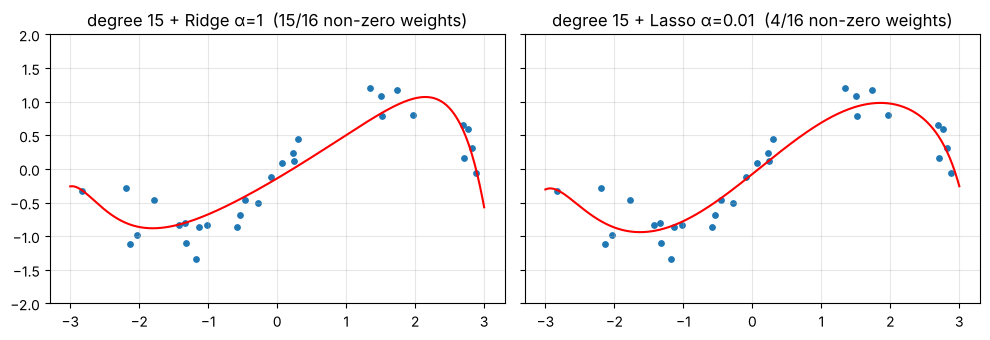

In [17]:
# Fix the degree-15 overfit with regularisation
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, reg) in zip(axes, [("Ridge α=1", Ridge(alpha=1)), ("Lasso α=0.01", Lasso(alpha=0.01, max_iter=50000))]):
    m = make_pipeline(PolynomialFeatures(15), StandardScaler(), reg).fit(xc.reshape(-1, 1), yc)
    ax.scatter(xc, yc, s=15); ax.plot(grid, m.predict(grid), "r"); ax.set_ylim(-2, 2)
    nz = np.sum(np.abs(m[-1].coef_) > 1e-6)
    ax.set_title(f"degree 15 + {name}  ({nz}/{len(m[-1].coef_)} non-zero weights)")
plt.tight_layout(); plt.show()

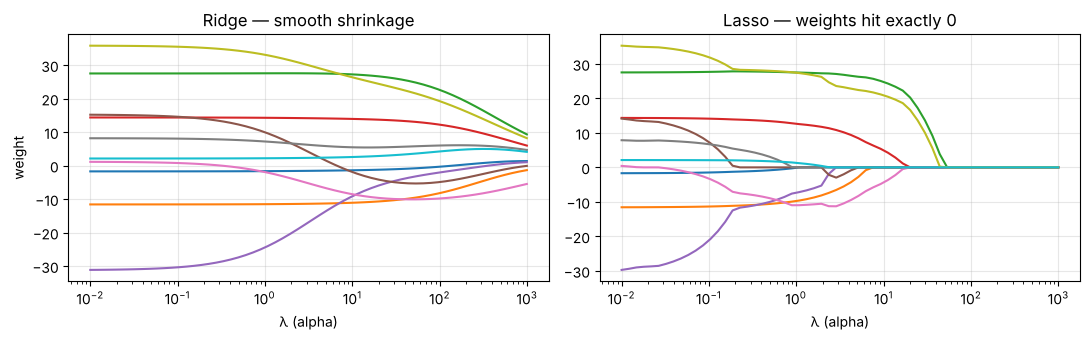

In [18]:
# Regularisation path: how weights shrink as λ grows
alphas = np.logspace(-2, 3, 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, Model, name in [(axes[0], Ridge, "Ridge — smooth shrinkage"), (axes[1], Lasso, "Lasso — weights hit exactly 0")]:
    coefs = [Model(alpha=a, max_iter=10000).fit(Xtr_s, ytr).coef_ for a in alphas]
    ax.plot(alphas, coefs); ax.set_xscale("log"); ax.set_xlabel("λ (alpha)"); ax.set_title(name)
axes[0].set_ylabel("weight"); plt.tight_layout(); plt.show()

## 10. Assumptions & common pitfalls
- **Linearity:** the true relationship must be (roughly) linear in your features. Check a **residual plot** — residuals vs predictions should look like random noise. A curve means you're missing a feature (e.g. x²).
- **Outliers** pull the line strongly (errors are *squared*). Consider MAE/Huber loss or investigate the outlier.
- **Multicollinearity:** highly correlated features → unstable weights. Ridge helps.
- **Extrapolation:** a line fitted on 50–150 m² houses says nothing reliable about 1000 m² castles.
- **Correlation ≠ causation:** a weight tells you association, not "changing x will change y".

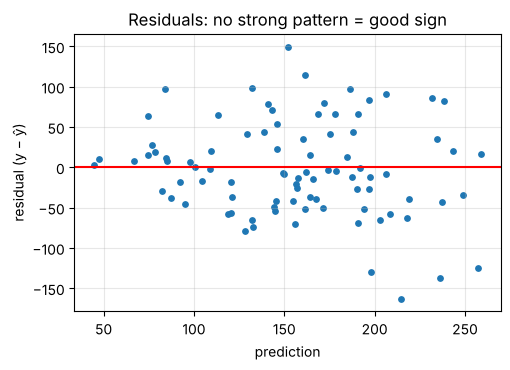

In [19]:
# Residual plot for the diabetes model
p = sk.predict(Xte_s)
plt.scatter(p, yte - p, s=15); plt.axhline(0, c="r")
plt.xlabel("prediction"); plt.ylabel("residual (y − ŷ)"); plt.title("Residuals: no strong pattern = good sign"); plt.show()

## 11. Key takeaways
- Linear regression: $\hat{y} = Xw + b$, trained by minimising **MSE**.
- Solve it exactly (normal equation) or iteratively (**gradient descent**: step opposite the gradient, scaled by the learning rate).
- **Scale features** before gradient descent.
- Too simple → underfit; too flexible → overfit. **Regularisation** (Ridge/Lasso) controls flexibility.

## 12. Exercises
1. In `gd_python`, print the loss every 100 epochs. How many epochs until it stops changing?
2. Implement **Lasso** with gradient descent (the derivative of |w| is sign(w)). Do weights become *exactly* zero? (Hint: no — that's why real Lasso uses *coordinate descent* with soft-thresholding; see `ml_from_scratch.py` → `LassoRegression`.)
3. Add an outlier `(x=1.9, y=-20)` to the toy data and refit. How much does the slope change?
4. Use `sklearn.model_selection.cross_val_score` to choose the best Ridge alpha for the diabetes data.

In [20]:
# Exercise 3 — solution
x_out, y_out = np.append(x, 1.9), np.append(y, -20)
print("slope without outlier:", round(fit_line_python(x.tolist(), y.tolist())[0], 3))
print("slope with one outlier:", round(fit_line_python(x_out.tolist(), y_out.tolist())[0], 3))

slope without outlier: 2.846
slope with one outlier: 1.313


In [21]:
# Exercise 4 — solution
from sklearn.model_selection import cross_val_score
for a in [0.01, 0.1, 1, 10, 100]:
    s = cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)), Xtr, ytr, cv=5, scoring="r2")
    print(f"alpha={a:<6} mean CV R² = {s.mean():.4f}")

alpha=0.01   mean CV R² = 0.5257
alpha=0.1    mean CV R² = 0.5258
alpha=1      mean CV R² = 0.5263
alpha=10     mean CV R² = 0.5268
alpha=100    mean CV R² = 0.5135


**Next:** [02 · Logistic Regression](02_logistic_regression.ipynb) — the same idea bent to predict categories.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §3.1–3.2 · `Calculus_Notes.md` Part 8 (gradient descent) · `Linear_Algebra_Notes.md` Part 6 (least squares) · code: `ml_from_scratch.py` → `LinearRegression`, `RidgeRegression`, `LassoRegression`.